# AquaGuard — Sistema Inteligente de Monitoramento e Prevenção de Enchentes
## Classificação didática de risco de enchentes com Machine Learning

Este notebook demonstra um protótipo acadêmico para classificar o risco de enchente em **baixo, moderado ou alto** a partir de chuva acumulada, nível do rio, saturação do solo, capacidade de drenagem e altitude.

**Atenção:** os dados são sintéticos e os rótulos são gerados por uma regra didática. As métricas avaliam a capacidade do modelo de reproduzir essa regra simulada; não representam precisão comprovada em enchentes reais.


## Instalação e bibliotecas

In [1]:
# No Google Colab, normalmente estas bibliotecas já estão disponíveis.
# Se necessário, descomente a linha abaixo:
# !pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

SEED = 42
np.random.seed(SEED)
print("Bibliotecas carregadas com sucesso.")


Bibliotecas carregadas com sucesso.






##  Criar dataset sintético

In [2]:
N = 2500

dados = pd.DataFrame({
    "chuva_24h_mm": np.random.gamma(shape=2.2, scale=22, size=N).clip(0, 180),
    "nivel_rio_m": np.random.normal(loc=2.4, scale=1.1, size=N).clip(0.2, 7),
    "saturacao_solo_pct": np.random.normal(loc=62, scale=20, size=N).clip(5, 100),
    "drenagem_pct": np.random.normal(loc=58, scale=22, size=N).clip(5, 100),
    "altitude_m": np.random.gamma(shape=2.0, scale=12, size=N).clip(1, 100)
})

# Regra didática para produzir rótulos sintéticos.
pontuacao = (
    (dados["chuva_24h_mm"] > 70).astype(int) * 2 +
    (dados["nivel_rio_m"] > 3.8).astype(int) * 2 +
    (dados["saturacao_solo_pct"] > 80).astype(int) +
    (dados["drenagem_pct"] < 30).astype(int) +
    (dados["altitude_m"] < 12).astype(int)
)

dados["risco"] = pd.cut(
    pontuacao,
    bins=[-1, 1, 3, 10],
    labels=["Baixo", "Moderado", "Alto"]
)

dados.head()


,chuva_24h_mm,nivel_rio_m,saturacao_solo_pct,drenagem_pct,altitude_m,risco
0,57.879167,2.783176,87.809215,53.584925,31.605301,Baixo
1,37.049372,1.412387,63.103985,49.096691,23.479863,Baixo
2,34.422964,1.863524,100.000000,80.651296,29.718991,Baixo
3,34.423402,3.581766,29.490155,100.000000,43.825546,Baixo
4,109.171711,2.946040,50.864425,78.982726,7.123713,Moderado


##  Análise exploratória dos dados

Dimensões do dataset: (2500, 6)


,chuva_24h_mm,nivel_rio_m,saturacao_solo_pct,drenagem_pct,altitude_m
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,49.024756,2.381732,62.032300,57.345423,24.429093
std,31.883690,1.090302,19.656761,20.940051,16.839387
min,0.376052,0.200000,5.000000,5.000000,1.000000
25%,25.378958,1.625351,48.865463,43.168297,11.768398
50%,42.486680,2.361694,62.152881,57.292196,20.551965
75%,64.784346,3.147430,75.874709,71.623950,32.933704
max,180.000000,6.281961,100.000000,100.000000,100.000000


\nDistribuição das classes:


,count
risco,
Baixo,1612
Moderado,789
Alto,99


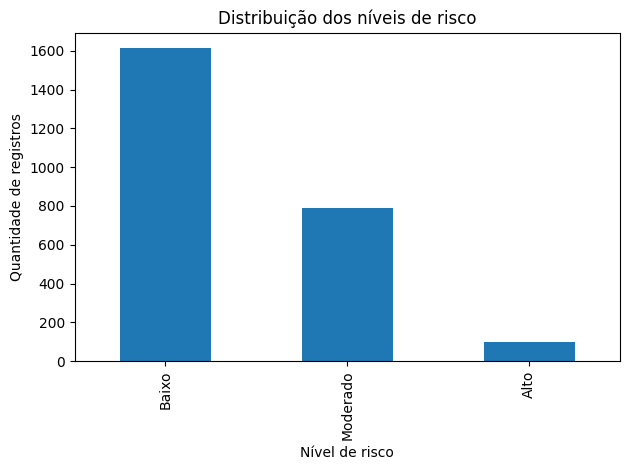

In [3]:
print("Dimensões do dataset:", dados.shape)
display(dados.describe())
print("\\nDistribuição das classes:")
display(dados["risco"].value_counts())

dados["risco"].value_counts().plot(kind="bar", title="Distribuição dos níveis de risco")
plt.xlabel("Nível de risco")
plt.ylabel("Quantidade de registros")
plt.tight_layout()
plt.show()


##  Preparação dos dados e divisão treino/teste

In [4]:
features = [
    "chuva_24h_mm", "nivel_rio_m", "saturacao_solo_pct",
    "drenagem_pct", "altitude_m"
]
X = dados[features]
y = dados["risco"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)


Treino: (2000, 5)
Teste: (500, 5)


## Treinamento do modelo Random Forest

In [5]:
modelo = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("classificador", RandomForestClassifier(
        n_estimators=200,
        random_state=SEED,
        class_weight="balanced",
        max_depth=10
    ))
])

modelo.fit(X_train, y_train)
print("Treinamento concluído.")


Treinamento concluído.


##  Avaliação do modelo

In [6]:
predicoes = modelo.predict(X_test)

acuracia = accuracy_score(y_test, predicoes)
f1_macro = f1_score(y_test, predicoes, average="macro")

print(f"Acurácia: {acuracia:.4f}")
print(f"F1-score macro: {f1_macro:.4f}")
print("\\nRelatório de classificação:")
print(classification_report(y_test, predicoes, zero_division=0))


Acurácia: 0.9900
F1-score macro: 0.9472
\nRelatório de classificação:
              precision    recall  f1-score   support

        Alto       1.00      0.75      0.86        20
       Baixo       1.00      1.00      1.00       322
    Moderado       0.97      1.00      0.98       158

    accuracy                           0.99       500
   macro avg       0.99      0.92      0.95       500
weighted avg       0.99      0.99      0.99       500



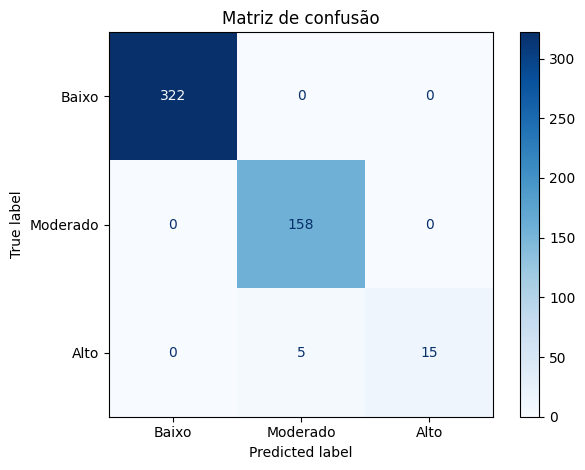

In [7]:
matriz = confusion_matrix(y_test, predicoes, labels=["Baixo", "Moderado", "Alto"])
disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=["Baixo", "Moderado", "Alto"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusão")
plt.tight_layout()
plt.show()


## Importância das variáveis

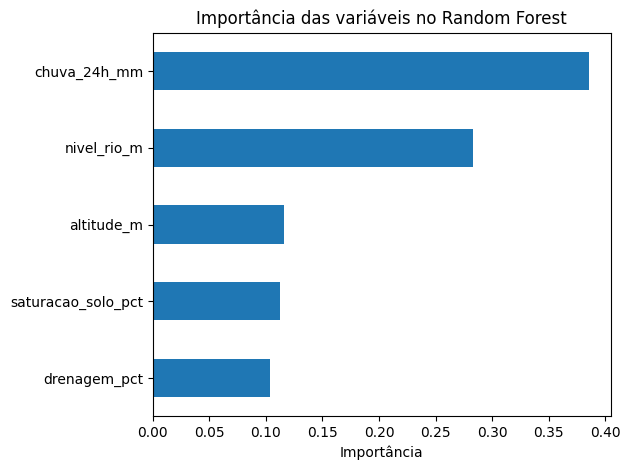

,importancia
chuva_24h_mm,0.385531
nivel_rio_m,0.283219
altitude_m,0.115735
saturacao_solo_pct,0.112185
drenagem_pct,0.103330


In [8]:
rf = modelo.named_steps["classificador"]
importancias = pd.Series(rf.feature_importances_, index=features).sort_values()

importancias.plot(kind="barh", title="Importância das variáveis no Random Forest")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

display(importancias.sort_values(ascending=False).to_frame("importancia"))


## Testar uma nova região

In [9]:
def avaliar_regiao(chuva_24h_mm, nivel_rio_m, saturacao_solo_pct, drenagem_pct, altitude_m):
    nova_regiao = pd.DataFrame([{
        "chuva_24h_mm": chuva_24h_mm,
        "nivel_rio_m": nivel_rio_m,
        "saturacao_solo_pct": saturacao_solo_pct,
        "drenagem_pct": drenagem_pct,
        "altitude_m": altitude_m
    }])
    classe = modelo.predict(nova_regiao)[0]
    probabilidades = modelo.predict_proba(nova_regiao)[0]
    confiancas = dict(zip(modelo.classes_, probabilidades))
    return classe, confiancas

# Exemplo ilustrativo; altere os valores para testar outros cenários.
classe, confiancas = avaliar_regiao(
    chuva_24h_mm=100,
    nivel_rio_m=4.5,
    saturacao_solo_pct=90,
    drenagem_pct=20,
    altitude_m=5
)

print("Classificação estimada:", classe)
print("Probabilidades estimadas:", {k: round(float(v), 3) for k, v in confiancas.items()})


Classificação estimada: Alto
Probabilidades estimadas: {'Alto': 0.92, 'Baixo': 0.0, 'Moderado': 0.08}


##  Salvar o modelo treinado

In [10]:
joblib.dump(modelo, "modelo_risco_enchente.joblib")
print("Modelo salvo em modelo_risco_enchente.joblib")


Modelo salvo em modelo_risco_enchente.joblib


##  Conclusão e limitações

O protótipo demonstra um fluxo básico de Machine Learning: geração/organização de dados, análise exploratória, divisão treino/teste, treinamento, avaliação e inferência para uma nova região.

**Limitações:** dataset sintético, rótulos derivados de regra artificial, ausência de validação com dados históricos reais e ausência de calibração operacional. Antes de uso público, o modelo precisaria ser treinado e validado com dados confiáveis de pluviômetros, sensores de rios, solo, topografia e registros oficiais, além de monitoramento contínuo e revisão por especialistas.
